In [358]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [359]:
conn=sqlite3.connect('customer_churn.db')
sql_query='''
select name
from sqlite_master
where type='table'

'''


tables=pd.read_sql(sql_query,conn)

#create dataframe for each table
for table_name in tables['name']:
    df=pd.read_sql(f"SELECT * FROM {table_name}",conn)
    globals()[f"df_{table_name}"]=df
    print(f"Created dataframe:df_{table_name}")

conn.close()
    

Created dataframe:df_db_customer
Created dataframe:df_db_subscription
Created dataframe:df_db_support


In [360]:
#Print table names and column names
conn=sqlite3.connect('customer_churn.db')

for table_name in tables['name']:
    print(f"\nTable Name:{table_name}")
    #Get column information
    column_query=f"PRAGMA table_info({table_name});"
    columns=pd.read_sql(column_query,conn)
    print("Column:")
    print(columns['name'].tolist())

#close connection
conn.close()


Table Name:db_customer
Column:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name:db_subscription
Column:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name:db_support
Column:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


In [361]:
# Data Cleaning

In [362]:
df_db_customer.head()
#df_db_customer.tail()



,customerid,name,country,state,gender,dob,interests,pincode
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00,travel,None
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00,NaN,None
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00,movie,None
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00,NaN,None
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00,drama,None


In [363]:
 df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  21 non-null     str   
 1   name        21 non-null     str   
 2   country     18 non-null     str   
 3   state       21 non-null     str   
 4   gender      21 non-null     str   
 5   dob         21 non-null     str   
 6   interests   4 non-null      str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 1.4+ KB


In [364]:
# a.rename col- name
# b. drop columns - interest and pincode
# c. change data type - dob
# d. data standardization - gender
# e. fix missing values -country
 

In [365]:
# a. rename col- name

df_db_customer.rename(columns={'name':'customer_name'},inplace=True)



In [366]:
# b. drop column - interest and pincode
df_db_customer.drop(columns=['interests','pincode'],inplace=True)

In [367]:
df_db_customer

,customerid,customer_name,country,state,gender,dob
0,0002-ORFBO,keshav,India,Maharashtra,Male,1982-04-12 00:00:00
1,0003-MKNFE,raghav,India,Karnataka,Male,1995-11-23 00:00:00
2,0004-TLHLJ,lalita,India,Delhi,Female,1978-02-15 00:00:00
3,0011-IGKFF,mohan,India,Nagaland,Male,2001-08-30 00:00:00
4,0013-EXCHZ,mira,India,Delhi,Female,1990-05-05 00:00:00
5,0013-MHZWF,durga,NaN,Delhi,Women,1988-12-10 00:00:00
6,0013-SMEOE,mina,India,Meghalaya,Female,1976-09-21 00:00:00
7,0014-BMAQU,madan,India,Rajasthan,Male,1999-03-14 00:00:00
8,0015-UOCOJ,maya,NaN,Kathmandu,Women,1985-07-07 00:00:00
9,0016-QLJIS,arjun,Nepal,Kathmandu,Male,1993-10-29 00:00:00


In [368]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   customerid     21 non-null     str  
 1   customer_name  21 non-null     str  
 2   country        18 non-null     str  
 3   state          21 non-null     str  
 4   gender         21 non-null     str  
 5   dob            21 non-null     str  
dtypes: str(6)
memory usage: 1.1 KB


In [369]:
# c. change data type -dob

df_db_customer['dob']=pd.to_datetime(df_db_customer['dob'])

In [370]:
# d. data standardization- gender
#df_db_customer['gender'].unique()

df_db_customer['gender']=df_db_customer['gender'].replace({'Men':'Male','Women':'Female'})

In [371]:
df_db_customer['gender'].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [372]:
# e. fix missing values- country

df_db_customer[df_db_customer['country'].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01


In [373]:
state_country_mapping=df_db_customer.dropna(subset=['country']).set_index('state')['country'].to_dict()

df_db_customer['country']=df_db_customer['country'].fillna(df_db_customer['state'].map(state_country_mapping))

In [374]:
df_db_customer[['country','state']]

,country,state
0,India,Maharashtra
1,India,Karnataka
2,India,Delhi
3,India,Nagaland
4,India,Delhi
5,India,Delhi
6,India,Meghalaya
7,India,Rajasthan
8,Nepal,Kathmandu
9,Nepal,Kathmandu


In [375]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,34
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,8
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88


In [376]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               21 non-null     str    
 1   subscription_start_date  21 non-null     str    
 2   subscription_type        21 non-null     str    
 3   renewal_date             21 non-null     str    
 4   plan_type                21 non-null     str    
 5   contract_type            21 non-null     str    
 6   cancellation_date        6 non-null      str    
 7   cancellation_reason      6 non-null      str    
 8   monthly_charges          21 non-null     float64
 9   cltv                     21 non-null     int64  
 10  churn_score              21 non-null     int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 1.9 KB


In [377]:
date_col=['subscription_start_date','renewal_date','cancellation_date']

df_db_subscription[date_col]=df_db_subscription[date_col].apply(pd.to_datetime)
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               21 non-null     str           
 1   subscription_start_date  21 non-null     datetime64[us]
 2   subscription_type        21 non-null     str           
 3   renewal_date             21 non-null     datetime64[us]
 4   plan_type                21 non-null     str           
 5   contract_type            21 non-null     str           
 6   cancellation_date        6 non-null      datetime64[us]
 7   cancellation_reason      6 non-null      str           
 8   monthly_charges          21 non-null     float64       
 9   cltv                     21 non-null     int64         
 10  churn_score              21 non-null     int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 1.9 KB


In [378]:
df_db_support.head()

,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0003-MKNFE,2024-08-28 00:00:00,N,60,None,service issue
1,0003-MKNFE,2024-08-28 00:00:00,Y,10,None,demaned refund
2,0013-EXCHZ,2024-01-20 00:00:00,Y,20,None,NaN
3,0013-MHZWF,2025-03-18 00:00:00,N,90,None,guidance to renew
4,0013-SMEOE,2024-11-01 00:00:00,N,30,None,NaN


In [379]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      9 non-null      str   
 1   complaint_date  9 non-null      str   
 2   escalations     9 non-null      str   
 3   csat_score      9 non-null      int64 
 4   col_1           0 non-null      object
 5   comment         4 non-null      str   
dtypes: int64(1), object(1), str(4)
memory usage: 564.0+ bytes


In [380]:
df_db_support.drop(columns=['col_1'],inplace=True)

In [381]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   customerid      9 non-null      str  
 1   complaint_date  9 non-null      str  
 2   escalations     9 non-null      str  
 3   csat_score      9 non-null      int64
 4   comment         4 non-null      str  
dtypes: int64(1), str(4)
memory usage: 492.0 bytes


In [382]:
df_db_support['complaint_date']=pd.to_datetime(df_db_support['complaint_date'])

In [383]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      9 non-null      str           
 1   complaint_date  9 non-null      datetime64[us]
 2   escalations     9 non-null      str           
 3   csat_score      9 non-null      int64         
 4   comment         4 non-null      str           
dtypes: datetime64[us](1), int64(1), str(3)
memory usage: 492.0 bytes


In [384]:
#3 Feature Engineering and Data Analysis

In [385]:
# crate a new column using existing column
df_db_subscription['churn_flag']=np.where(df_db_subscription['cancellation_date'].notna(),1,0)

In [386]:
df_db_subscription.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,8,0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,88,1


In [387]:
df=(df_db_subscription.merge(df_db_customer,on='customerid',how='left').merge(df_db_support,on='customerid',how='left'))

In [388]:
df_db_subscription.shape

(21, 12)

In [389]:
df.shape

(23, 21)

In [390]:
df_db_subscription['customerid'].nunique()

21

In [391]:
df_db_customer['customerid'].nunique()

21

In [392]:
df_db_support['customerid'].nunique()

7

In [393]:
df_db_support['customerid'].size

df_db_support['complaint_count']=df_db_support.groupby('customerid')['customerid'].transform('count')

In [394]:
df_db_support.drop(columns=['comment'],inplace=True)

In [395]:
df_db_support

,customerid,complaint_date,escalations,csat_score,complaint_count
0,0003-MKNFE,2024-08-28,N,60,2
1,0003-MKNFE,2024-08-28,Y,10,2
2,0013-EXCHZ,2024-01-20,Y,20,1
3,0013-MHZWF,2025-03-18,N,90,1
4,0013-SMEOE,2024-11-01,N,30,1
5,0017-IUDMW,2024-04-10,Y,25,1
6,0019-EFAEP,2024-09-27,Y,30,1
7,0022-TCJCI,2024-09-13,Y,10,2
8,0022-TCJCI,2024-09-14,N,90,2


In [396]:
df_db_support=df_db_support.sort_values('complaint_date').drop_duplicates('customerid',keep='last')

In [397]:
#first fix support duplicates and then merge
df=(df_db_subscription.merge(df_db_customer,on='customerid',how='left').merge(df_db_support,on='customerid',how='left'))


In [398]:
df.shape

(21, 21)

In [399]:
df.to_csv('exported_churn_data.csv',index=False)

In [400]:
# now coming towards Data analysis

In [401]:
# 1 Churn_rate

In [402]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count'],
      dtype='str')

In [403]:
churn_rate=df['churn_flag'].mean()*100
print("Churn Rate =",round(churn_rate,2),"%")

Churn Rate = 28.57 %


In [404]:
# 2 = Retention rate
retention_rate=100-churn_rate
print("Retention Rate =",round(retention_rate,2),"%")

Retention Rate = 71.43 %


In [405]:
df.head(3)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,churn_flag,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,0,keshav,India,Maharashtra,Male,1982-04-12,NaT,NaN,NaN,NaN
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,1,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,Y,10.0,2.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,0,lalita,India,Delhi,Female,1978-02-15,NaT,NaN,NaN,NaN


In [406]:
churn_by_plan=df.groupby('plan_type')['churn_flag'].mean().mul(100).round(2).reset_index()

In [407]:
churn_by_plan

,plan_type,churn_flag
0,Basic,60.00
1,Premium,14.29
2,Standard,22.22


In [408]:
# H W
#4 a. Churn by state + sum(revenue) & count of users 
# 4 b. Churn by subscription type + sum(revenue) & count of users
# age of the customer



In [409]:
#5  ARPU - Avg Revenue per user
arpu=df['monthly_charges'].mean()
print('ARPU =',round(arpu,2))

ARPU = 18.85


In [410]:
#6 Avg customer tenure
# count of days users has used our service : cancellation date else current date;
today=pd.Timestamp.today()

df['tenure_days']= np.where(
    df['cancellation_date'].notna(),
    (df['cancellation_date'] - df['subscription_start_date']).dt.days,
    (today - df['subscription_start_date']).dt.days
)

df.head()
avg_tenure=df['tenure_days'].mean()
print("Avg Tenure(Days) =",avg_tenure)

Avg Tenure(Days) = 1565.142857142857


In [411]:
 #Revenue at risk - revenue lost from churned users
revenue_at_risk=df.loc[df['churn_flag']==1,'monthly_charges'].sum()
print("Revenue at Risk(Rs 'k')= ", revenue_at_risk)

Revenue at Risk(Rs 'k')=  73.94


In [412]:
# Esclation Rate
escalation_rate=(df['escalations']=='Y').mean()*100
print("Escalation Rate =",round(escalation_rate,2),"%")

Escalation Rate = 19.05 %


In [413]:
# 9 Avg Complaint Per User 
df['complaint_count'].sum() / df['customerid'].nunique()

np.float64(0.42857142857142855)

In [414]:
# 10 Correlation( Escalation vs churn)

df['escalations'] = (
    df['escalations']
    .map({'Y': 1, 'N': 0})
    .fillna(0)
    .astype(int)
)
corr_df=df[['escalations','churn_flag']].dropna()

correlation=corr_df['escalations'].corr(df['churn_flag'])
print('Correlation between escalation vs churn is=',round(correlation,2))



Correlation between escalation vs churn is= 0.77


In [415]:
df.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,tenure_days
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,...,keshav,India,Maharashtra,Male,1982-04-12,NaT,0,NaN,NaN,2046.0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,1,10.0,2.0,1501.0
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,...,lalita,India,Delhi,Female,1978-02-15,NaT,0,NaN,NaN,1431.0
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaT,NaN,22.99,1725,...,mohan,India,Nagaland,Male,2001-08-30,NaT,0,NaN,NaN,2721.0
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,mira,India,Delhi,Female,1990-05-05,2024-01-20,1,20.0,1.0,419.0


In [416]:
print(df['escalations'].value_counts(dropna=False))

escalations
0    17
1     4
Name: count, dtype: int64


In [417]:
for name, data in [
    ('df', df)
]:
    print(f"\n{name}:")
    print(data['escalations'].value_counts(dropna=False))


df:
escalations
0    17
1     4
Name: count, dtype: int64


In [418]:
print(df['escalations'].value_counts(dropna=False))
print(df['churn_flag'].value_counts(dropna=False))
print(df[['escalations', 'churn_flag']].dtypes)

escalations
0    17
1     4
Name: count, dtype: int64
churn_flag
0    15
1     6
Name: count, dtype: int64
escalations    int64
churn_flag     int64
dtype: object


In [419]:
print(df['escalations'].isnull().sum())
print(df['escalations'].unique())
print(df['escalations'].head(10))

0
[0 1]
0    0
1    1
2    0
3    0
4    1
5    0
6    0
7    0
8    0
9    0
Name: escalations, dtype: int64


In [420]:
df['escalations'] = df['escalations'].fillna(0)

In [421]:
print(df[['escalations', 'churn_flag']].corr())

             escalations  churn_flag
escalations     1.000000    0.766965
churn_flag      0.766965    1.000000


In [422]:
print(df['escalations'].value_counts(dropna=False))
print(df['escalations'].nunique())
print(df['churn_flag'].value_counts())

escalations
0    17
1     4
Name: count, dtype: int64
2
churn_flag
0    15
1     6
Name: count, dtype: int64


In [423]:
df = pd.read_csv('exported_churn_data.csv')
print(df['escalations'].isnull().sum())
print(df[['escalations', 'churn_flag']].head(10))

14
  escalations  churn_flag
0         NaN           0
1           Y           1
2         NaN           0
3         NaN           0
4           Y           1
5           N           0
6           N           1
7         NaN           0
8         NaN           0
9         NaN           0


In [424]:
# 11 Churn risk - create a column using existiing col

conditions=[
    (df['churn_score']<50),
    (df['churn_score']>=50) & (df['churn_score']<70),
    (df['churn_score']>=70)
    
]
choices=['low','med','high']
df['churn_risk']=np.select(conditions,choices,default='unknown')



In [461]:
df[['churn_risk','churn_score']].tail()

,churn_risk,churn_score
16,med,62
17,low,27
18,high,99
19,low,7
20,low,47


In [426]:
# 4 . Visualization using Matplotlib


In [462]:
df_visual=df.copy()

In [463]:
df_visual.head()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,...,customer_name,country,state,gender,dob,complaint_date,escalations,csat_score,complaint_count,churn_risk
0,0002-ORFBO,2021-03-15,Refferal,2025-03-15,Standard,Annual,NaN,NaN,13.99,627,...,keshav,India,Maharashtra,Male,1982-04-12,NaN,0,NaN,NaN,low
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,...,raghav,India,Karnataka,Male,1995-11-23,2024-08-28,1,10.0,2.0,high
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaN,NaN,6.99,210,...,lalita,India,Delhi,Female,1978-02-15,NaN,0,NaN,NaN,low
3,0011-IGKFF,2019-05-10,Paid,2025-05-10,Premium,Annual,NaN,NaN,22.99,1725,...,mohan,India,Nagaland,Male,2001-08-30,NaN,0,NaN,NaN,low
4,0013-EXCHZ,2023-01-05,Refferal,2024-01-05,Standard,Monthly,2024-02-28,Too expensive,13.99,195,...,mira,India,Delhi,Female,1990-05-05,2024-01-20,1,20.0,1.0,high


In [429]:
df_visual.shape
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'churn_risk'],
      dtype='str')

In [430]:
print(df_visual['cancellation_date'].dtype)

str


In [431]:
df_visual['cancellation_date']=pd.to_datetime(
    df_visual['cancellation_date'],
    errors='coerce'
)

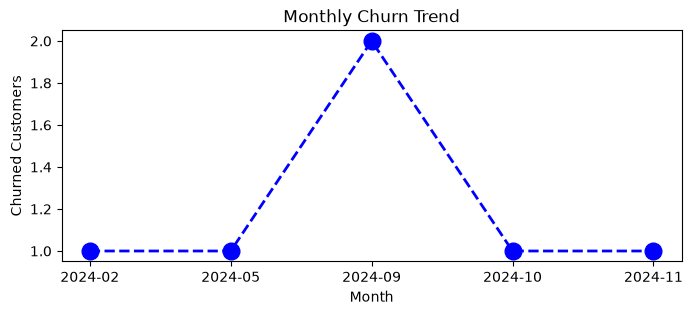

In [432]:
# 4.1 Monthly churn trend (time series kpi)

df_visual['cancellation_month']=df_visual['cancellation_date'].dt.to_period('M')

churn_trend=df_visual[df_visual['churn_flag']==1].groupby('cancellation_month').size()


plt.figure(figsize=(8,3))
plt.plot(churn_trend.index.astype(str),churn_trend.values,color='blue', marker='o', linestyle='dashed',  linewidth=2, markersize=12)

plt.title('Monthly Churn Trend')
plt.xlabel('Month')
plt.ylabel('Churned Customers')
plt.show()





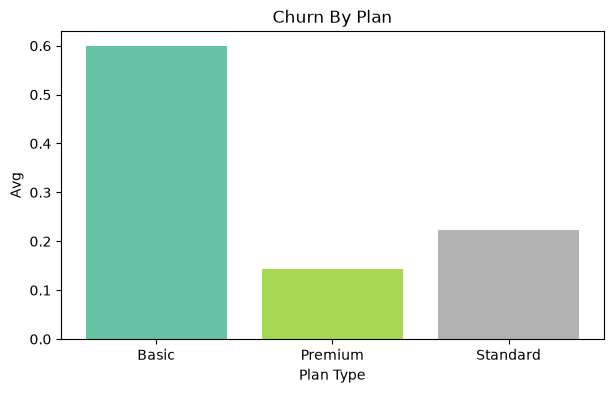

In [433]:
#4.2 Churn by Plan type

churn_plan=df_visual.groupby('plan_type')['churn_flag'].mean()

colors=plt.cm.Set2(np.linspace(0,1,len(churn_plan)))

plt.figure(figsize=(7,4))

plt.bar(churn_plan.index,churn_plan.values,color=colors)

plt.title('Churn By Plan')
plt.xlabel('Plan Type')
plt.ylabel('Avg')

plt.show()

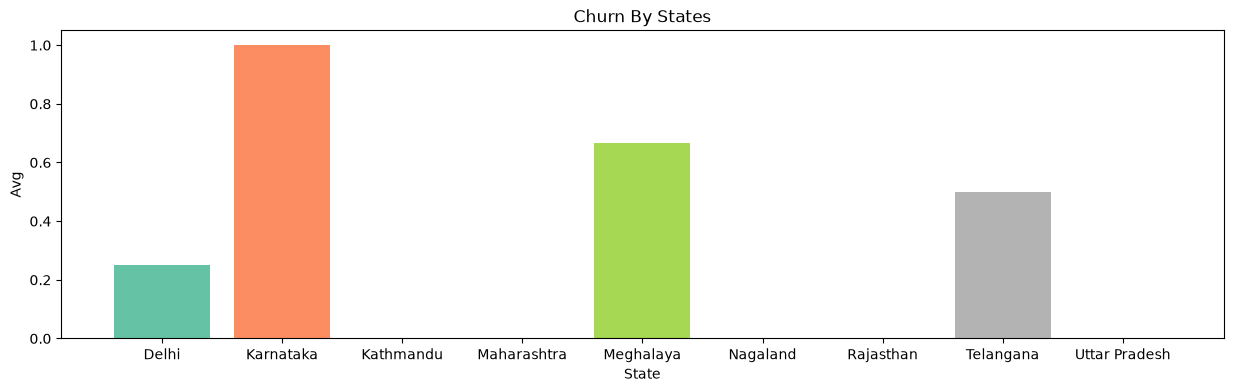

In [434]:
# 4.3 Churn by states
churn_plan=df_visual.groupby('state')['churn_flag'].mean()

colors=plt.cm.Set2(np.linspace(0,1,len(churn_plan)))

plt.figure(figsize=(15,4))

plt.bar(churn_plan.index,churn_plan.values,color=colors)

plt.title('Churn By States')
plt.xlabel('State')
plt.ylabel('Avg')

plt.show()


In [435]:
# Visualization using Seaborn


In [436]:
# encoding - convert str to numeric so that we can find corr btween features
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'churn_risk', 'cancellation_month'],
      dtype='str')

In [450]:


df = pd.read_csv("exported_churn_data.csv")

print(df['escalations'].value_counts(dropna=False))

escalations
NaN    14
Y       4
N       3
Name: count, dtype: int64


In [452]:
df['escalations'] = (
    df['escalations']
    .map({'Y': 1, 'N': 0})
    .fillna(0)
    .astype(int)
)

print(df['escalations'].value_counts())

escalations
0    17
1     4
Name: count, dtype: int64


In [453]:
df_visual = df.copy()

In [454]:
print(df['escalations'].value_counts())
print(df_visual['escalations'].value_counts())

escalations
0    17
1     4
Name: count, dtype: int64
escalations
0    17
1     4
Name: count, dtype: int64


In [464]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complaint_count',
       'churn_risk'],
      dtype='str')

In [465]:
# incorrect method of encoding - as numbers are not assigned based on priority
df_encoded=df_visual[['plan_type', 'contract_type','churn_score','churn_flag','churn_risk','escalations']]

categorial_cols=['plan_type','contract_type','churn_risk']

for col in categorial_cols:
    df_encoded[col]=df_encoded[col].astype('category').cat.codes

In [466]:
df_visual[['plan_type', 'contract_type','churn_score','churn_flag','churn_risk','escalations']].head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,Standard,Annual,12,0,low,0
1,Premium,Annual,91,1,high,1
2,Basic,Monthly,34,0,low,0
3,Premium,Annual,8,0,low,0
4,Standard,Monthly,88,1,high,1


In [467]:
df_encoded.head()

,plan_type,contract_type,churn_score,churn_flag,churn_risk,escalations
0,2,0,12,0,1,0
1,1,0,91,1,0,1
2,0,1,34,0,1,0
3,1,0,8,0,1,0
4,2,1,88,1,0,1


<Axes: >

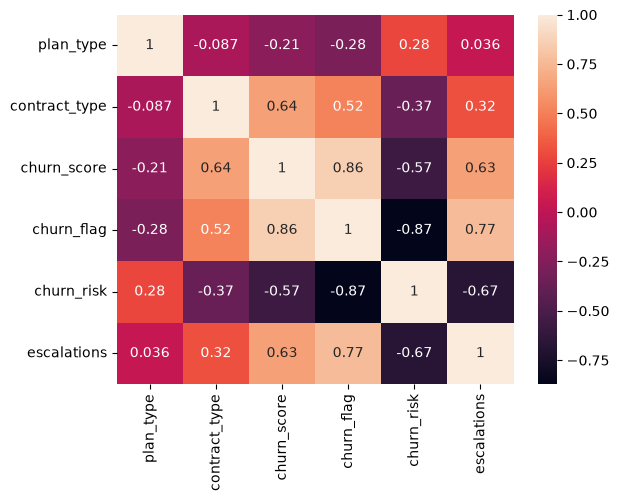

In [468]:
#Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(),annot=True)

In [469]:
# Correct method of encoding -  based on priority
df_encoded=df_visual[['plan_type', 'contract_type','churn_score','churn_flag','churn_risk','escalations']]

order_mappings={
    'plan_type':['Basic','Standard','Premium'],
    'contract_type':['Monthly','Annual'],
    'churn_risk':['low','med','high']}

for col,order in order_mappings.items():
    df_encoded[col]=pd.Categorical(df_encoded[col].astype('category'),categories=order,ordered=True).codes

<Axes: >

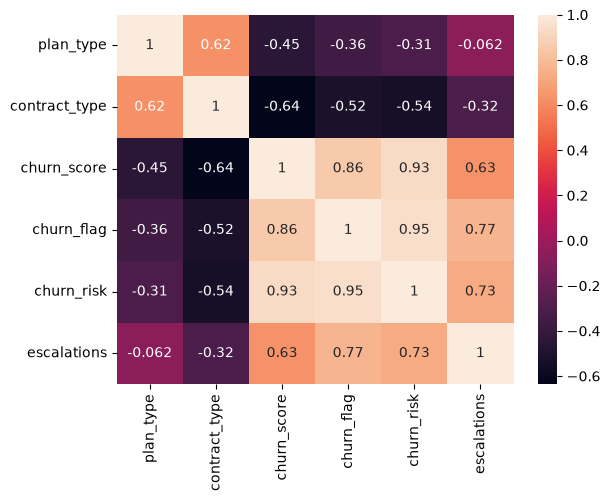

In [470]:
sns.heatmap(df_encoded.corr(),annot=True)

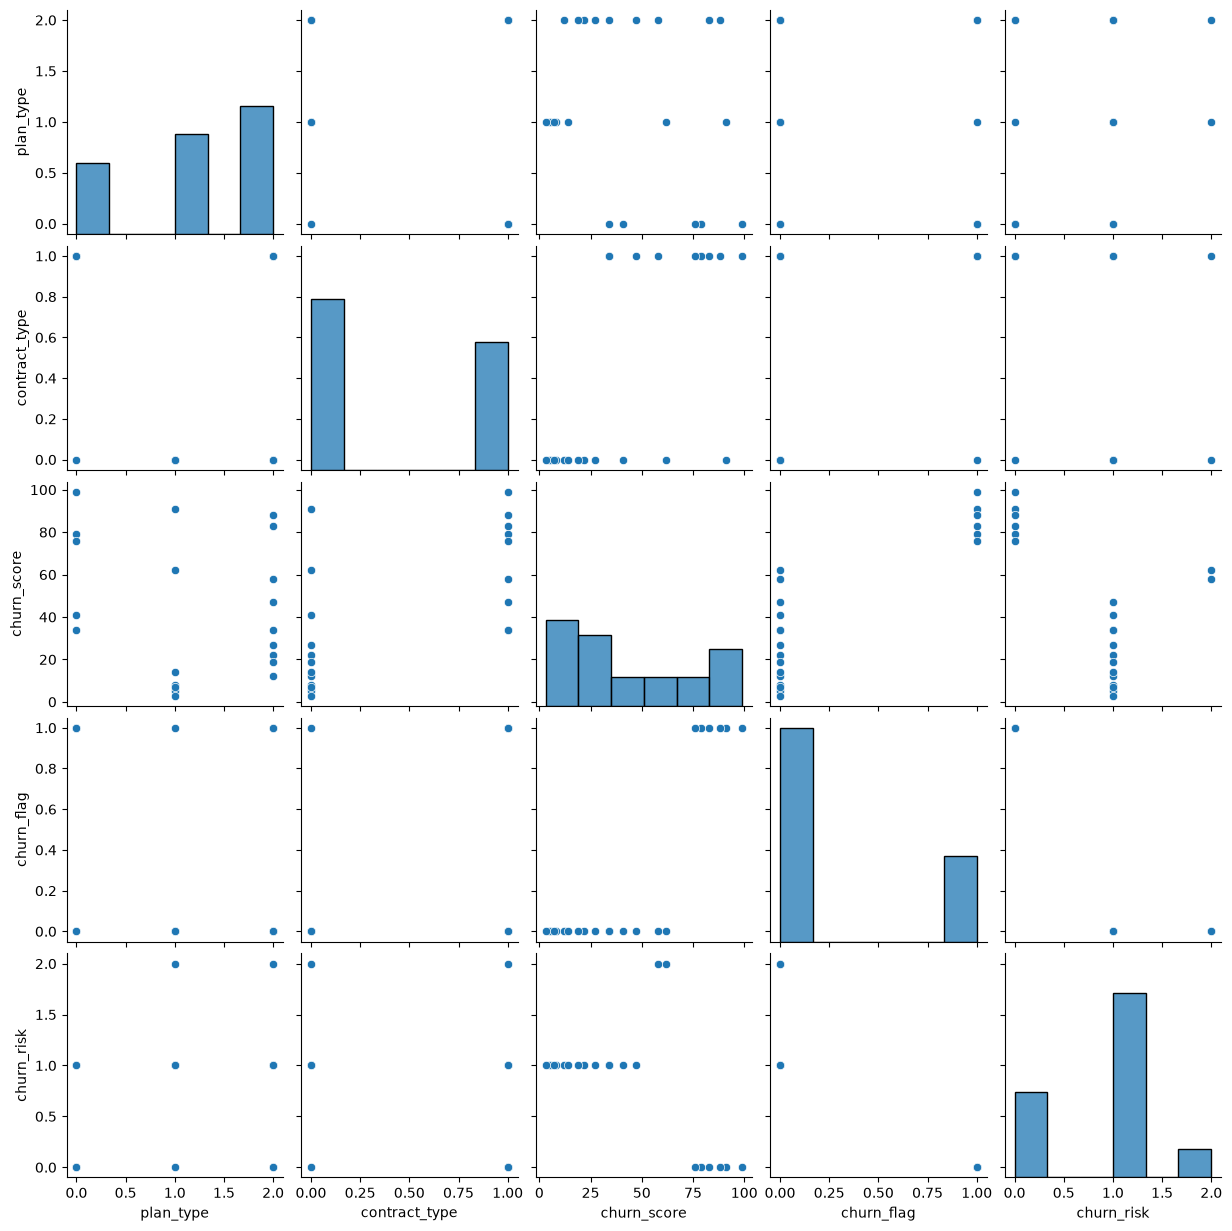

In [448]:
# pairplot

sns.pairplot(df_encoded)

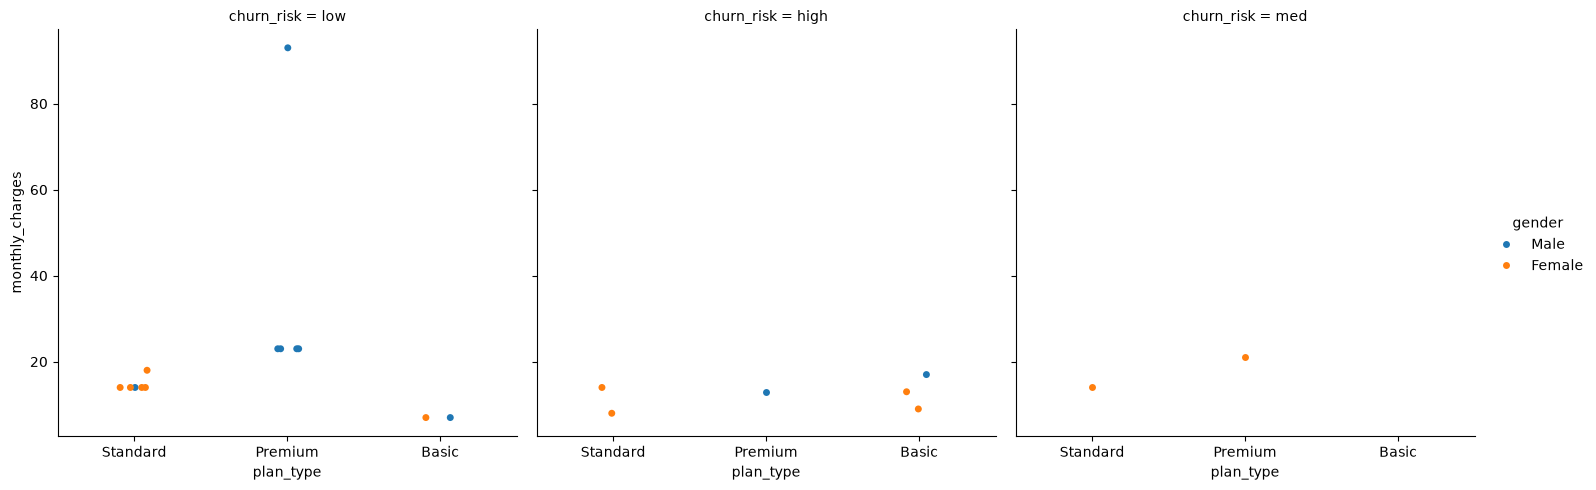

In [449]:
# catplt/Facegrid plot
sns.catplot(data=df_visual,
           x='plan_type',
           y='monthly_charges',
           hue='gender',
           col='churn_risk')

In [471]:
#pivot table

In [473]:
pd.pivot_table(
    df_visual,
    values='churn_flag',
    index='plan_type',
    aggfunc='mean'
).reset_index()

,plan_type,churn_flag
0,Basic,0.600000
1,Premium,0.142857
2,Standard,0.222222


In [474]:
pd.pivot_table(
    df_visual,
    values=['monthly_charges','customerid','churn_flag'],
    index='plan_type',
    aggfunc={
        'monthly_charges':'sum',
        'customerid':'nunique',
        'churn_flag':'mean'
        
    }
).reset_index()

,plan_type,churn_flag,customerid,monthly_charges
0,Basic,0.600000,5,52.95
1,Premium,0.142857,7,218.93
2,Standard,0.222222,9,123.91


In [475]:
# working with SQL in Python (pandas)

In [480]:
#create database in sql
conn=sqlite3.connect('test_database.sqlite')

#table details
conn.execute("CREATE TABLE project (first_name TEXT,country TEXT,budget INTEGER)")

# commit and save
conn.commit()

In [483]:
# insert data
cursor = conn.cursor()

cursor.execute(
    """
        INSERT INTO project VALUES
        ('Madhav','india','5000'),
        ('Rishabh','Germany','2500'),
        ('Vishakha','India','3500')
        
    
    """
)

#commit and save

conn.commit()
print("Data Inserted successfully!")


Data Inserted successfully!


In [486]:
# check inserted data in table

conn=sqlite3.connect('test_database.sqlite')
query=""" SELECT * FROM project """

df_results=pd.read_sql(query,conn)

df_results.head()

,first_name,country,budget
0,Madhav,india,5000
1,Rishabh,Germany,2500
2,Vishakha,India,3500


In [487]:
#aggregation

conn=sqlite3.connect('test_database.sqlite')
query="""

    SELECT country,sum(budget) as total_budget
    FROM project
    GROUP BY country
   
"""
df_agg=pd.read_sql(query,conn)

df_agg.head()

,country,total_budget
0,Germany,2500
1,India,3500
2,india,5000


In [488]:
conn.close()